# Task 1: N-Queens Problem with Propositional Logic (PySAT Glucose3)

This notebook demonstrates the solution and experimental evaluation for the N-Queens problem using Propositional Logic (CNF) and the `Glucose3` solver.

In [1]:
from nqueens_cnf import NQueensCNF, run_experiments
import matplotlib.pyplot as plt

for n_demo in [4, 8]:
    solver = NQueensCNF(n_demo)
    res = solver.solve()
    print(f"=== N = {n_demo} ===")
    print(f"Number of variables: {res['num_variables']}")
    print(f"Number of CNF clauses: {res['num_clauses']}")
    print(f"Solver time: {res['solver_time']:.6f} s")
    print(solver.format_board())
    print()

=== N = 4 ===
Number of variables: 16
Number of CNF clauses: 80
Solver time: 0.000029 s
. . Q .
Q . . .
. . . Q
. Q . .

=== N = 8 ===
Number of variables: 64
Number of CNF clauses: 736
Solver time: 0.000074 s
. . Q . . . . .
. . . . . Q . .
. . . Q . . . .
. Q . . . . . .
. . . . . . . Q
. . . . Q . . .
. . . . . . Q .
Q . . . . . . .



In [2]:
n_values = [4, 8, 12, 16, 20, 25, 30, 40, 50]
results = run_experiments(n_values)

    N |  Variables |    CNF Clauses |  Solver Time (s) |  Total Time (s)
------------------------------------------------------------------------
    4 |         16 |             80 |         0.000013 |        0.000154
    8 |         64 |            736 |         0.000071 |        0.001108
   12 |        144 |           2608 |         0.000128 |        0.002465
   16 |        256 |           6336 |         0.003580 |        0.009135
   20 |        400 |          12560 |         0.007343 |        0.018592
   25 |        625 |          24825 |         0.115268 |        0.139896
   30 |        900 |          43240 |         0.017249 |        0.064591
   40 |       1600 |         103520 |         0.013472 |        0.138035
   50 |       2500 |         203400 |         0.094892 |        0.267756


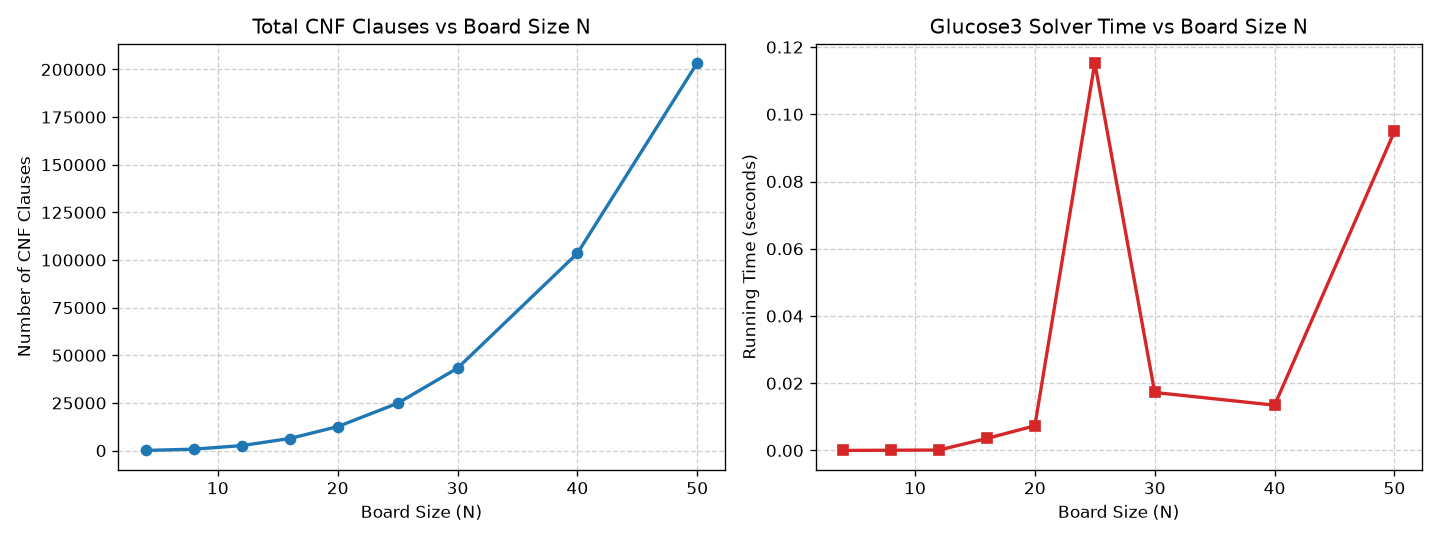

In [3]:
ns = [r['n'] for r in results]
clauses = [r['num_clauses'] for r in results]
times = [r['solver_time'] for r in results]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ns, clauses, marker='o', color='tab:blue', linewidth=2)
ax1.set_title('Total CNF Clauses vs Board Size N')
ax1.set_xlabel('Board Size (N)')
ax1.set_ylabel('Number of CNF Clauses')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(ns, times, marker='s', color='tab:red', linewidth=2)
ax2.set_title('Glucose3 Solver Time vs Board Size N')
ax2.set_xlabel('Board Size (N)')
ax2.set_ylabel('Running Time (seconds)')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('cnf_experiments.png', dpi=150)
plt.show()

Vì bài toán yêu cầu tìm 1 nghiệm bất kỳ chứ không phải là tìm all nghiệm nên bộ giải Glu sẽ rẽ nhánh tìm kiếm theo hẻuistic: Với n=30 và n=40, nhánh nó chọn mai mắn dẫn thẳng tới nghiệm đúng rất nhanh, còn nhánh n30 nó đi nhầm vào nhánh bế tắc nên phải quay lui (backtrack) nhiều lần hơn trước khi tìm thấy nghiệm